# Jour 3 - EDA (Pandas, Matplotlib, Seaborn)
Chaque graphique est suivi d'une interprétation générée à partir des chiffres réels. **Relisez-la devant le graphique et reformulez-la avec vos mots** dans le rapport.

In [18]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
%matplotlib inline
from src.cleaning.clean_data import load_clean
import src.eda.eda_plots as eda
df = load_clean()
print(df.shape)
df.head()

(2000, 14)


,movie_id,title,overview,release_date,runtime,original_language,status,genres,keywords,budget,revenue,popularity,vote_average,vote_count
0,11,Star Wars,Princess Leia is captured and held hostage by ...,1977-05-25,121.0,en,Released,"[Adventure, Action, Science Fiction]","[empire, galaxy, rebellion, android, hermit, s...",11000000.0,775398007.0,34.3206,8.207,22927
1,12,Finding Nemo,"Nemo, an adventurous young clownfish, is unexp...",2003-05-30,100.0,en,Released,"[Animation, Family, Adventure]","[fish, sydney, australia, parent child relatio...",94000000.0,940335536.0,37.4962,7.822,21029
2,13,Forrest Gump,A man with a low IQ has accomplished great thi...,1994-06-23,142.0,en,Released,"[Comedy, Drama, Romance]","[new year's eve, vietnam war, vietnam veteran,...",55000000.0,677387716.0,36.0453,8.461,30542
3,14,American Beauty,"Lester Burnham, a depressed suburban father in...",1999-09-15,122.0,en,Released,[Drama],"[estate agent, adultery, coming out, first tim...",15000000.0,356296601.0,19.7344,7.997,13393
4,15,Citizen Kane,Newspaper magnate Charles Foster Kane is taken...,1941-04-17,119.0,en,Released,"[Mystery, Drama]","[media tycoon, florida, art collector, newspap...",839727.0,23218000.0,11.3980,7.968,6248


## 1. Valeurs manquantes

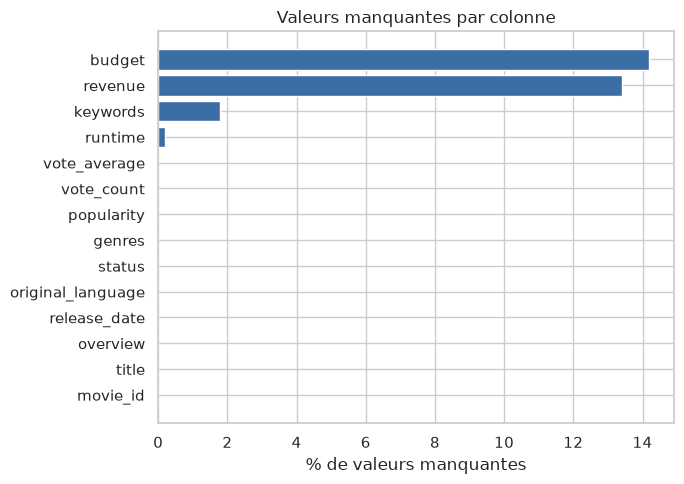

Colonnes avec plus de 10 % de manquants : budget (14 %), revenue (13 %). Ces valeurs sont des informations inconnues de TMDB, pas des zéros : elles seront imputées dans un Pipeline (sur le train uniquement) et signalées par l'indicateur `has_budget`.


In [19]:
print(eda.plot_missing(df, show=True))

## 2. Distribution des notes

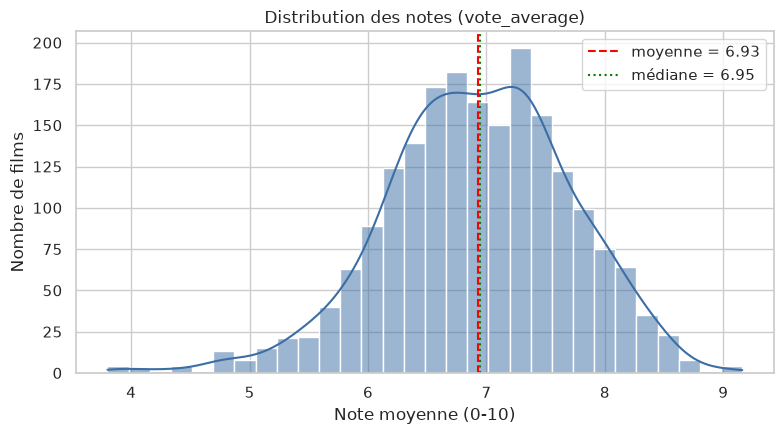

La note moyenne est 6.93 (médiane 6.95, écart-type 0.79). La distribution est à peu près symétrique et 82 % des films ont une note entre 6 et 8 : les notes extrêmes sont rares, la note seule discrimine peu les films.


In [20]:
print(eda.plot_vote_average(df, show=True))

## 3. Distribution de la popularité

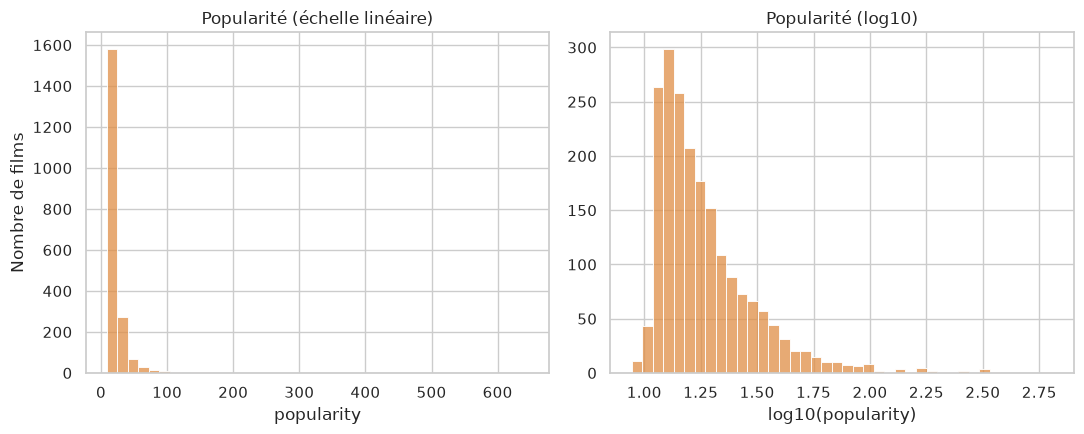

La popularité est très asymétrique vers la droite (longue queue de valeurs élevées) : médiane 16.0 contre un maximum de 646. Quelques films concentrent l'essentiel de la popularité, ce qui écrase le graphique linéaire. L'échelle logarithmique (à droite) rend la distribution lisible : une transformation log sera utile.


In [21]:
print(eda.plot_popularity(df, show=True))

## 4. Distribution du nombre de votes

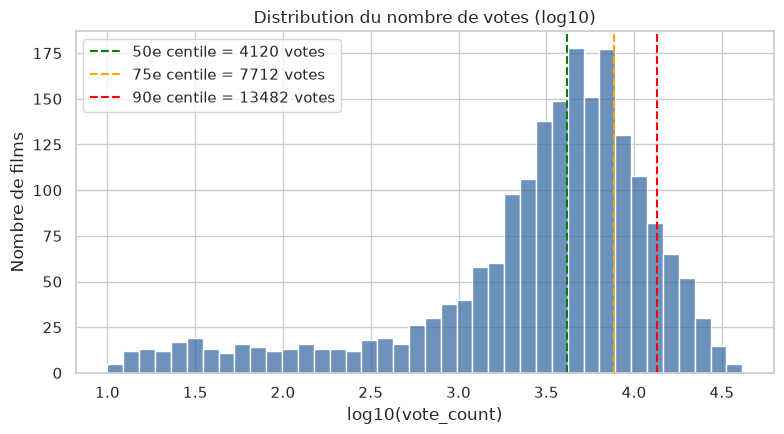

Le nombre de votes est très asymétrique vers la droite (longue queue de valeurs élevées) : médiane 4120, 75e centile 7712, 90e centile 13482, maximum 41307. Cette distribution guidera le choix du seuil de `high_engagement` au Jour 5 : la médiane donne des classes équilibrées, un centile plus élevé isole les films vraiment à fort engagement (classes déséquilibrées).


In [22]:
print(eda.plot_vote_count(df, show=True))

## 5. Films par genre

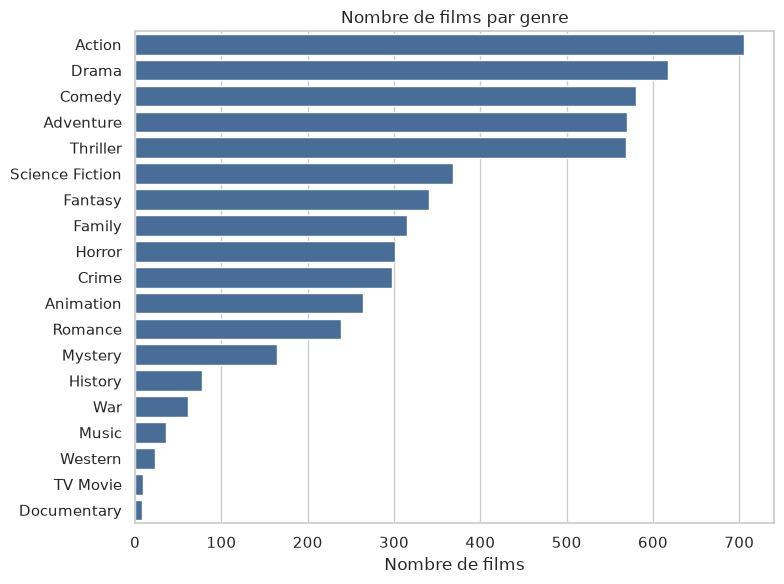

Les genres les plus présents sont Action (705 films, 35 % du catalogue), Drama (618 films, 31 % du catalogue), Comedy (580 films, 29 % du catalogue). Un film pouvant avoir plusieurs genres, la somme des barres dépasse le nombre de films (2000). Le genre le plus rare est Documentary (8 films) : les déséquilibres entre genres peuvent influencer les clusters et les modèles.


In [23]:
print(eda.plot_genres(df, show=True))

## 6. Sorties par année

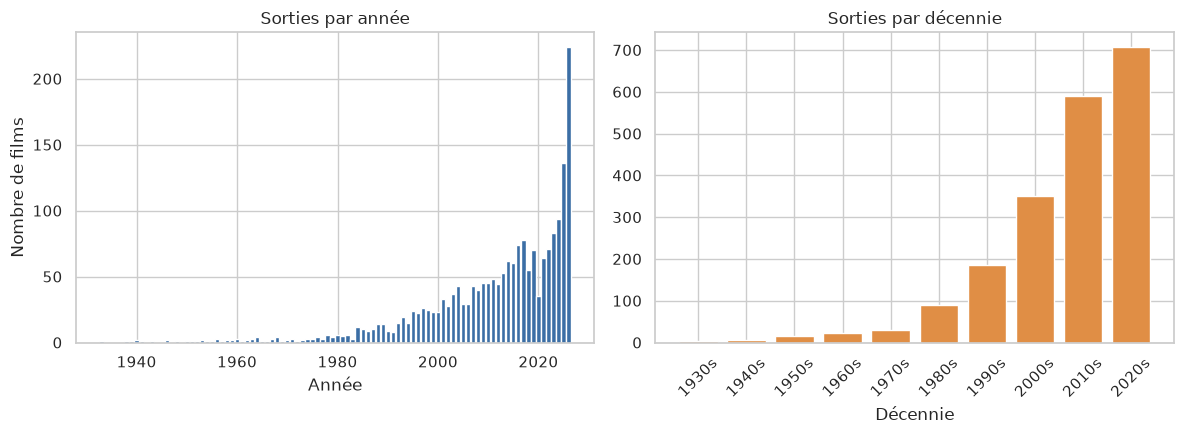

Le catalogue couvre de 1933 à 2026. L'année la plus représentée est 2026 (224 films) et 82 % des films sont sortis depuis 2000. Le catalogue est donc fortement orienté vers les films récents (effet du tri par popularité à l'extraction), biais à mentionner : les conclusions valent surtout pour le cinéma récent.


In [24]:
print(eda.plot_years(df, show=True))

## 7. Durée

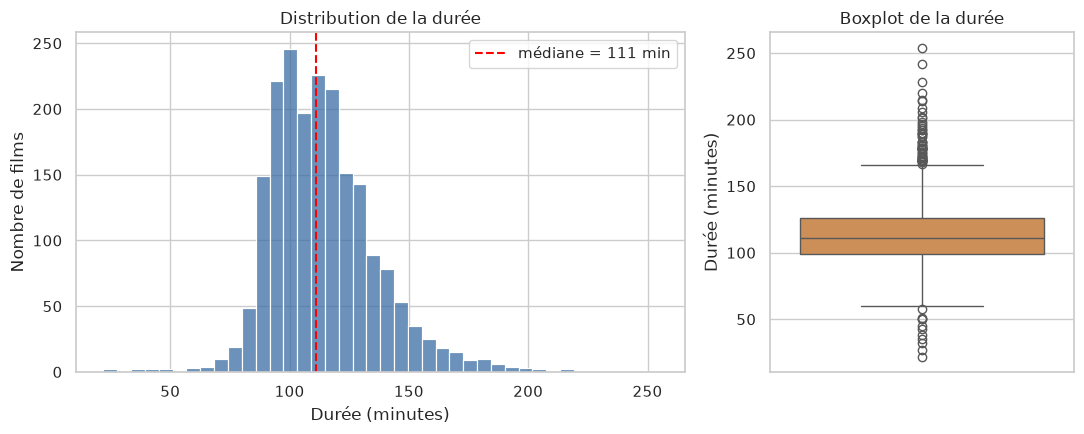

La durée médiane est de 111 minutes, la moitié des films durant entre 99 et 126 min. La distribution est asymétrique vers la droite. Le boxplot signale 67 valeurs aberrantes (durées très courtes ou très longues, maximum 254 min) : ce sont de vrais films atypiques, on les conserve, et les seuils fixes de `runtime_category` limitent leur influence.


In [25]:
print(eda.plot_runtime(df, show=True))

## 8. Budget vs revenus

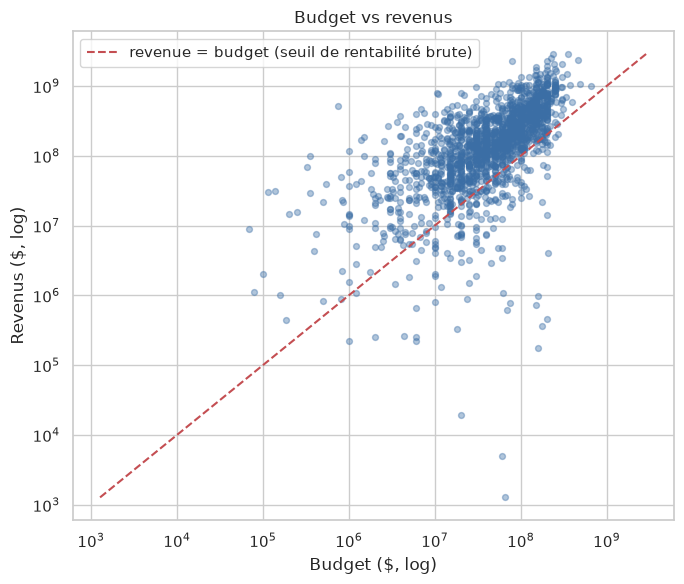

Sur les 1662 films dont budget et revenus sont connus (83 % du catalogue), la corrélation de Spearman est de 0.68 : plus le budget est élevé, plus les revenus tendent à l'être. 90 % des films sont au-dessus de la droite revenue = budget. Observez la dispersion verticale : à budget égal, les revenus varient fortement. Les films sans budget ou revenus connus sont exclus du graphique.


In [26]:
print(eda.plot_budget_revenue(df, show=True))

## 9. Votes vs popularité

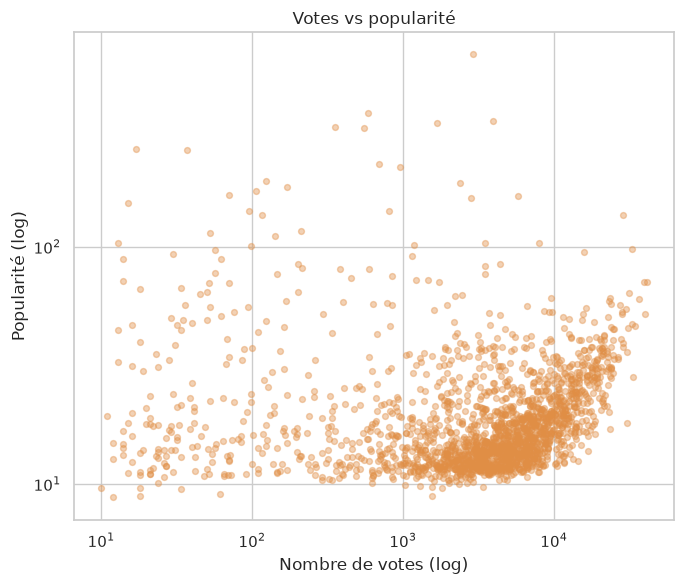

La corrélation de Spearman entre votes et popularité est 0.29 (faible). Les deux mesures capturent en partie la même chose (l'attention du public). Point crucial pour la classification : si la cible est construite à partir de `vote_count`, `popularity` en est un proxy et pourrait provoquer un Data Leakage : nous l'écartons des features.


In [27]:
print(eda.plot_votes_popularity(df, show=True))

## 10. Boxplots

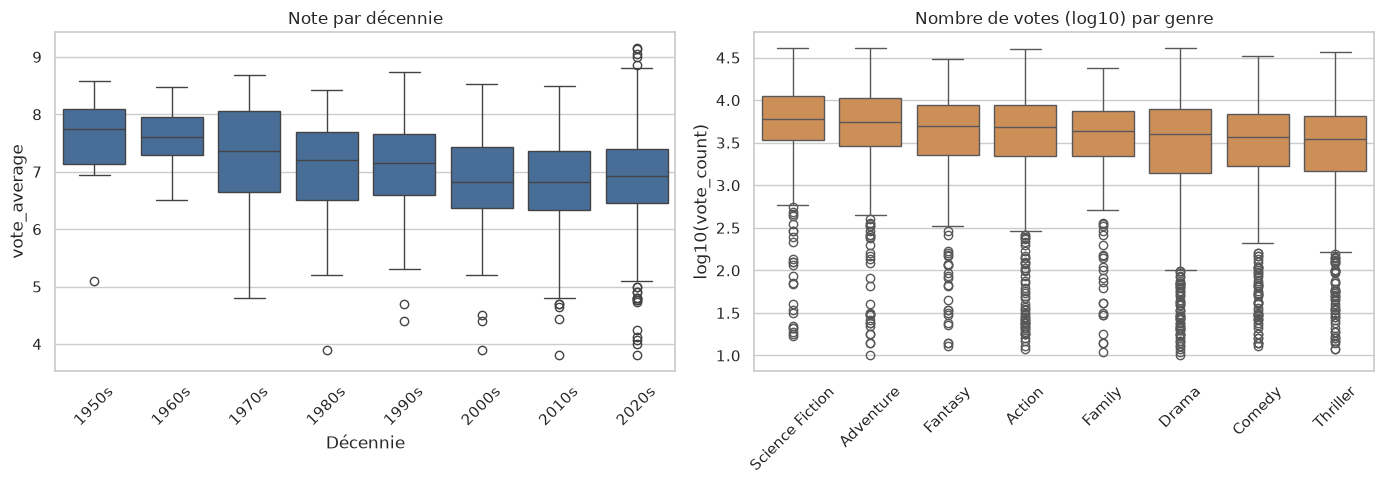

Note médiane par décennie : la plus élevée pour les 1950s (7.74), la plus basse pour les 2000s (6.83). Les films anciens encore présents dans le catalogue sont probablement des classiques : biais de survie à mentionner. Côté engagement, le genre avec le plus de votes en médiane est Science Fiction (≈ 6086 votes) et le moins engageant Thriller (≈ 3501 votes), soit un rapport de 1.7. Le genre semble donc lié à l'engagement et sera une feature utile.


In [29]:
print(eda.plot_boxplots(df, show=True))

## 11. Corrélations

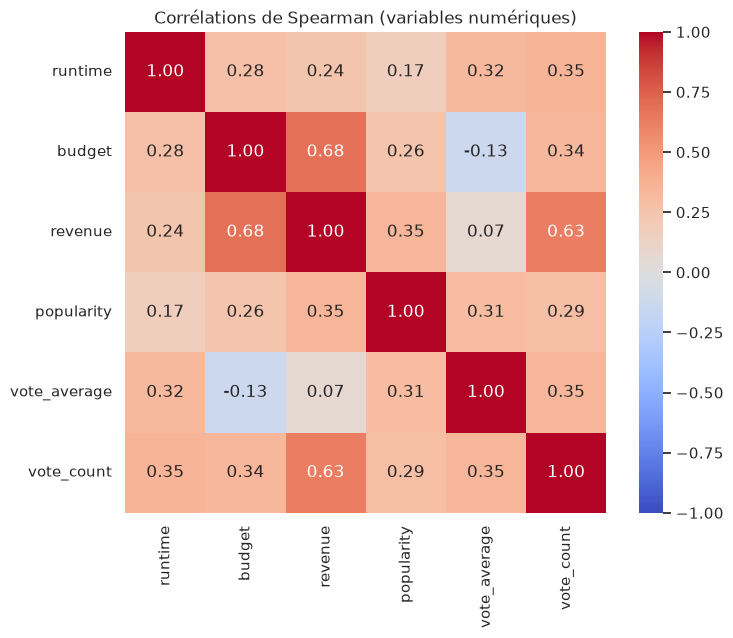

Les paires les plus corrélées sont : budget / revenue (0.68), revenue / vote_count (0.63), runtime / vote_count (0.35). On utilise Spearman car les variables sont très asymétriques (Pearson serait dominé par les valeurs extrêmes). Les variables fortement corrélées entre elles sont redondantes pour les modèles linéaires, et celles liées à `vote_count` sont des sources potentielles de leakage.


In [30]:
print(eda.plot_correlation(df, show=True))

## Sauvegarde de tous les graphiques + fichier d'interprétations

In [32]:
_ = eda.run_eda(df)